# Land surface temperature from GOES-16 NetCDF files

GOES-16 is a NOAA geostationary weather satellite. Its Advanced Baseline Imager (ABI) feeds a Level 2 product,
Land Surface Temperature (LST), that NOAA writes as one NetCDF-4 file per hour for the continental U.S. ("CONUS")
sector. This notebook:

1. lists the hourly LST files for one day straight from the public S3 bucket,
2. opens one file with xarray, applies the product's quality flags and turns the satellite's fixed-grid
   coordinates into latitude and longitude,
3. maps the afternoon skin temperature and compares the daily cycle over four kinds of land surface,
4. runs the same per-file step over three days of hourly files in parallel with Ray.

**Data.** NOAA GOES-R series ABI products on the AWS Registry of Open Data:
<https://registry.opendata.aws/noaa-goes/>, bucket `s3://noaa-goes16`, product `ABI-L2-LSTC`, laid out as
`ABI-L2-LSTC/<year>/<day of year>/<hour>/OR_ABI-L2-LSTC-M6_G16_s<start time>_e<end time>_c<created>.nc`.
GOES-16 was the operational GOES-East satellite until 4 April 2025, when GOES-19 replaced it, so the `noaa-goes16`
archive ends in early April 2025. The dates used here (13 to 15 July 2023, during a long heat wave in the U.S.
Southwest) stay fixed. The `noaa-goes19` bucket carries the same product for recent dates.

**License and attribution.** GOES-R series data are produced by NOAA. They are a work of the U.S. Government, in
the public domain, and NOAA Open Data Dissemination (NODD) data are free to use. NOAA asks for attribution, does not
allow stating or implying NOAA endorsement, and asks that modified data (such as the plots here) not be presented
as original NOAA data. Credit: NOAA GOES-R Series ABI Level 2 Land Surface Temperature, via NODD on AWS.

**Requirements:** `pip install xarray h5netcdf s3fs numpy pandas pyproj matplotlib ray`

All reads are anonymous; no cloud account is needed. One file is about 3 MB. The main analysis downloads 9 files
(about 30 MB); the Ray section downloads 72 (about 220 MB).

In [1]:
import io
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyproj
import s3fs
import xarray as xr

fs = s3fs.S3FileSystem(anon=True)  # anonymous access to the public bucket

PRODUCT = "noaa-goes16/ABI-L2-LSTC"
YEAR, DAY_OF_YEAR = 2023, 196  # 15 July 2023

# Regions to compare: name -> (south, north, west, east) in degrees.
REGIONS = {
    "Sonoran Desert, AZ": (32.5, 33.5, -113.5, -112.5),
    "Central Valley farmland, CA": (36.0, 36.8, -120.3, -119.5),
    "Cascade Range forest, OR": (44.0, 45.0, -122.5, -121.5),
    "Corn Belt cropland, IA": (41.5, 42.5, -94.5, -93.5),
}


def hourly_files(year, day_of_year):
    """All LST files for one day, sorted by scan start time."""
    return sorted(fs.glob(f"{PRODUCT}/{year}/{day_of_year:03d}/*/*.nc"))


files = hourly_files(YEAR, DAY_OF_YEAR)
print(f"{len(files)} files for {YEAR} day {DAY_OF_YEAR}; first: {files[0].rsplit('/', 1)[-1]}")
print(f"one file is {fs.size(files[0]) / 1e6:.1f} MB")

24 files for 2023 day 196; first: OR_ABI-L2-LSTC-M6_G16_s20231960001176_e20231960003549_c20231960004542.nc
one file is 2.7 MB


## 1. Open one file

The file is downloaded into memory and opened with the `h5netcdf` engine. xarray applies the stored scale factor,
offset and fill value, so `LST` comes out in kelvin with missing pixels as NaN. `DQF` is the data quality flag:
0 = high, 1 = medium, 2 = low quality, 3 = no retrieval (for example ocean or cloud).

In [2]:
def open_lst(path):
    """Download one LST file and open it from memory."""
    data = s3fs.S3FileSystem(anon=True).cat_file(path)
    return xr.open_dataset(io.BytesIO(data), engine="h5netcdf")


afternoon = [p for p in files if p.split("/")[-2] == "20"][0]  # 20 UTC, early afternoon in the West
with open_lst(afternoon) as ds:
    print(ds["LST"].attrs["long_name"], "-", ds["LST"].dims, ds["LST"].shape)
    print("DQF meanings:", ds["DQF"].attrs["flag_meanings"])
    proj_attrs = dict(ds["goes_imager_projection"].attrs)
    x, y = ds["x"].values, ds["y"].values
    lst_k = ds["LST"].values
    dqf = ds["DQF"].values
    scan_time = pd.Timestamp(ds["t"].values)

print("scan time:", scan_time)
for flag, name in enumerate(["high", "medium", "low", "none"]):
    print(f"  DQF {flag} ({name}): {np.mean(dqf == flag):6.1%} of pixels")

ABI L2+ Land Surface (Skin) Temperature - ('y', 'x') (1500, 2500)
DQF meanings: high_quality_retrieval_qf, medium_quality_retrieval_qf, low_quality_retrieval_qf, no_retrieval_qf


scan time: 2023-07-15 20:02:36.348336
  DQF 0 (high):  10.8% of pixels
  DQF 1 (medium):   8.0% of pixels
  DQF 2 (low):   9.1% of pixels
  DQF 3 (none):  70.8% of pixels


## 2. From fixed-grid angles to latitude and longitude

ABI images are on a "fixed grid": `x` and `y` are scan angles in radians as seen from the satellite. Multiplying
them by the satellite height gives coordinates in the geostationary projection described by the
`goes_imager_projection` variable, which pyproj can convert to longitude and latitude. The CONUS grid is the same
in every file, so this is done once.

In [3]:
def fixed_grid_lonlat(x, y, proj_attrs):
    """Longitude and latitude (degrees) of every pixel of an ABI fixed grid."""
    height = proj_attrs["perspective_point_height"]
    crs = pyproj.CRS.from_cf(proj_attrs)
    xx, yy = np.meshgrid(x.astype("float64") * height, y.astype("float64") * height)
    to_lonlat = pyproj.Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
    return to_lonlat.transform(xx, yy)


lon, lat = fixed_grid_lonlat(x, y, proj_attrs)
lon = np.where(np.isfinite(lon), lon, np.nan)  # pixels that miss the Earth come back as inf
lat = np.where(np.isfinite(lat), lat, np.nan)
print(f"grid {lon.shape}, longitude {np.nanmin(lon):.1f} to {np.nanmax(lon):.1f}, "
      f"latitude {np.nanmin(lat):.1f} to {np.nanmax(lat):.1f}")

# Flat pixel indices inside each region, reused for every file.
region_index = {}
for name, (south, north, west, east) in REGIONS.items():
    inside = (lat >= south) & (lat <= north) & (lon >= west) & (lon <= east)
    region_index[name] = np.flatnonzero(inside)
    print(f"{name:30s} {inside.sum():5d} pixels")

grid (1500, 2500), longitude -151.7 to -52.9, latitude 14.6 to 56.6
Sonoran Desert, AZ              1278 pixels
Central Valley farmland, CA      615 pixels
Cascade Range forest, OR         651 pixels
Corn Belt cropland, IA          1249 pixels


## 3. Afternoon map

Keep high- and medium-quality retrievals (DQF 0 and 1) and convert to degrees Celsius. LST is the temperature of
the surface itself (the "skin"), not of the air, so bare ground in sun gets much hotter than the air above it.
Clouds have no LST, which is why parts of the map are blank.

The image is drawn on its native fixed grid, as the satellite sees it from above the equator at 75°W, with
latitude and longitude lines drawn as contours of the arrays computed above. A few pixels in the corner of the
sector look past the edge of the Earth and have no latitude or longitude, so the data is not regridded here.

pixels with a usable value: 18.8%


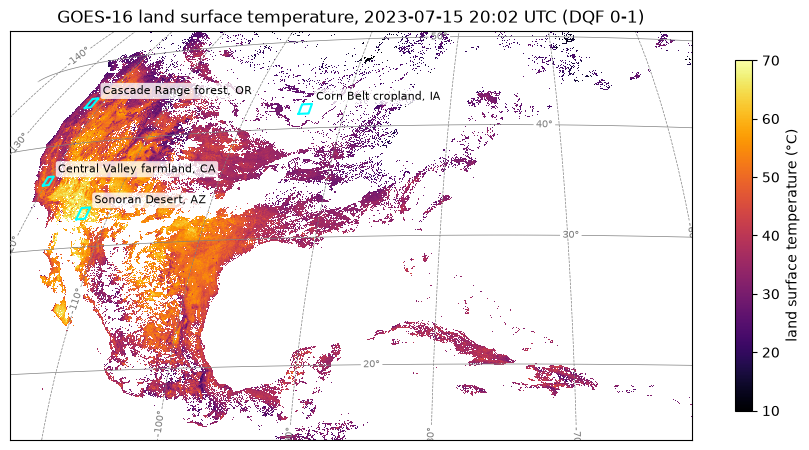

In [4]:
lst_c = np.where(dqf <= 1, lst_k - 273.15, np.nan)
print(f"pixels with a usable value: {np.isfinite(lst_c).mean():.1%}")

height = proj_attrs["perspective_point_height"]
x_km, y_km = x * height / 1e3, y * height / 1e3  # fixed-grid coordinates in km
to_grid = pyproj.Transformer.from_crs("EPSG:4326", pyproj.CRS.from_cf(proj_attrs), always_xy=True)

fig, ax = plt.subplots(figsize=(11, 6.5))
img = ax.imshow(lst_c, extent=[x_km[0], x_km[-1], y_km[-1], y_km[0]], cmap="inferno", vmin=10, vmax=70,
                interpolation="nearest")
for values, levels in ((lon, range(-140, -50, 10)), (lat, range(20, 60, 10))):
    cs = ax.contour(x_km, y_km, values, levels=list(levels), colors="grey", linewidths=0.5)
    ax.clabel(cs, fmt="%d°", fontsize=7)
for name, (south, north, west, east) in REGIONS.items():
    edge_lon = np.r_[np.linspace(west, east, 20), np.full(20, east), np.linspace(east, west, 20), np.full(20, west)]
    edge_lat = np.r_[np.full(20, south), np.linspace(south, north, 20), np.full(20, north), np.linspace(north, south, 20)]
    gx, gy = to_grid.transform(edge_lon, edge_lat)
    ax.plot(gx / 1e3, gy / 1e3, color="cyan", lw=1.5)
    ax.annotate(name, (gx.max() / 1e3, gy.max() / 1e3), xytext=(3, 3), textcoords="offset points", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, lw=0))
fig.colorbar(img, ax=ax, shrink=0.7, label="land surface temperature (°C)")
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f"GOES-16 land surface temperature, {scan_time:%Y-%m-%d %H:%M} UTC (DQF 0-1)")
plt.show()

## 4. The per-file step: regional statistics

`region_lst` is the step that runs once per file: download, mask by quality, then return the scan time and, for
each region, the share of its pixels that were usable ("clear") and the mean LST over those pixels. When less
than `MIN_CLEAR_PERCENT` of a region is usable, mostly because of cloud, the mean is left empty rather than
computed from a few pixels at the cloud edges. The step only needs the pixel indices computed above, not the
full latitude/longitude arrays.

In [5]:
MIN_CLEAR_PERCENT = 20


def region_lst(path, region_index, min_clear_percent=MIN_CLEAR_PERCENT):
    """Scan time, mean LST (deg C) and clear-pixel share for each region in one file."""
    with open_lst(path) as ds:
        lst = ds["LST"].values
        good = ds["DQF"].values <= 1
        scan = pd.Timestamp(ds["t"].values)
    values = np.where(good, lst - 273.15, np.nan).ravel()
    row = {"time": scan}
    for name, idx in region_index.items():
        v = values[idx]
        clear_percent = 100.0 * np.isfinite(v).sum() / idx.size
        row[name] = float(np.nanmean(v)) if clear_percent >= min_clear_percent else np.nan
        row[name + " clear %"] = float(clear_percent)
    return row


print(region_lst(afternoon, region_index))

{'time': Timestamp('2023-07-15 20:02:36.348336'), 'Sonoran Desert, AZ': 65.852294921875, 'Sonoran Desert, AZ clear %': 82.7073552425665, 'Central Valley farmland, CA': 45.29602813720703, 'Central Valley farmland, CA clear %': 99.67479674796748, 'Cascade Range forest, OR': 34.77946853637695, 'Cascade Range forest, OR clear %': 97.38863287250383, 'Corn Belt cropland, IA': nan, 'Corn Belt cropland, IA clear %': 0.0}


## 5. The daily cycle, every three hours

Run the step on every third hourly file of the day (8 files), one after another. The x axis is local solar time
for each region (UTC plus longitude / 15 hours), so that noon is when the sun is highest at that place.

In [6]:
three_hourly = files[::3]

t0 = time.time()
day = pd.DataFrame([region_lst(p, region_index) for p in three_hourly]).set_index("time")
serial_seconds = time.time() - t0
print(f"{len(three_hourly)} files read one after another in {serial_seconds:.0f} s "
      f"({serial_seconds / len(three_hourly):.1f} s per file)")
day.round(1).T.rename(columns=lambda t: t.strftime("%H:%M UTC"))

8 files read one after another in 9 s (1.1 s per file)


time,00:02 UTC,03:02 UTC,06:02 UTC,09:02 UTC,12:02 UTC,15:02 UTC,18:02 UTC,21:02 UTC
"Sonoran Desert, AZ",55.8,40.6,36.2,33.5,31.2,43.0,61.2,64.8
"Sonoran Desert, AZ clear %",100.0,89.4,79.0,89.1,96.0,51.9,75.5,89.3
"Central Valley farmland, CA",40.4,29.7,24.2,22.4,20.6,29.2,41.4,45.8
"Central Valley farmland, CA clear %",98.4,100.0,100.0,100.0,100.0,99.5,94.1,99.3
"Cascade Range forest, OR",29.9,23.9,19.0,16.9,15.5,23.5,33.1,34.9
"Cascade Range forest, OR clear %",100.0,100.0,100.0,100.0,99.5,98.8,94.6,97.8
"Corn Belt cropland, IA",NaN,20.5,19.9,19.1,18.6,25.6,NaN,NaN
"Corn Belt cropland, IA clear %",6.3,91.4,98.4,100.0,83.2,30.5,3.4,0.2


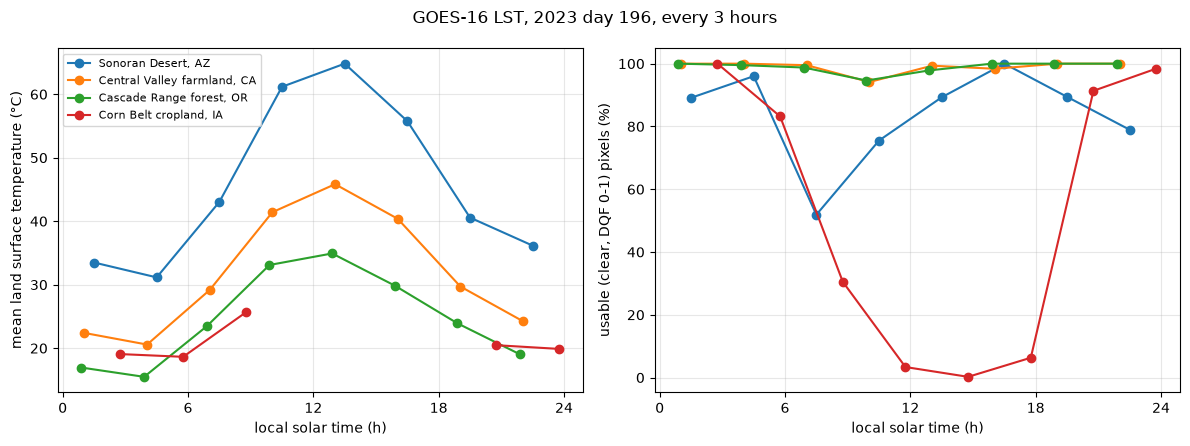

day-night range of the regional mean (deg C; NaN where clouds hid part of the day):
Sonoran Desert, AZ             33.7
Central Valley farmland, CA    25.3
Cascade Range forest, OR       19.4
Corn Belt cropland, IA          NaN


In [7]:
def solar_hour(times, west, east):
    """Local solar hour (0-24) at the centre longitude of a region."""
    hours = times.hour + times.minute / 60 + (west + east) / 2 / 15
    return np.mod(hours, 24)


fig, (ax_t, ax_c) = plt.subplots(1, 2, figsize=(12, 4.5))
for name, (south, north, west, east) in REGIONS.items():
    h = solar_hour(day.index, west, east)
    order = np.argsort(h)
    ax_t.plot(h[order], day[name].values[order], "o-", label=name)
    ax_c.plot(h[order], day[name + " clear %"].values[order], "o-", label=name)
ax_t.set_ylabel("mean land surface temperature (°C)")
ax_c.set_ylabel("usable (clear, DQF 0-1) pixels (%)")
for ax in (ax_t, ax_c):
    ax.set_xlabel("local solar time (h)")
    ax.set_xticks(range(0, 25, 6))
    ax.grid(alpha=0.3)
ax_t.legend(fontsize=8)
fig.suptitle(f"GOES-16 LST, {YEAR} day {DAY_OF_YEAR}, every 3 hours")
fig.tight_layout()
plt.show()

temps = day[list(REGIONS)]
swing = (temps.max() - temps.min()).where(temps.notna().all())
print("day-night range of the regional mean (deg C; NaN where clouds hid part of the day):")
print(swing.round(1).to_string())

On this day the bare desert surface has the largest day-night range, the forest the smallest, and the irrigated
valley sits in between: plants and moist soil spend part of the incoming sunlight on evaporating water, which
keeps their surfaces cooler. Over Iowa, afternoon clouds covered most of the region (right panel), so its daytime
means are left out where fewer than 20% of its pixels were usable.

## Scaling out with Ray

Each file is processed independently, so the per-file step parallelises directly. Wrap `region_lst` as a Ray task
and submit one task per hourly file for three days (13 to 15 July, 72 files). The small `region_index` dictionary
is put in the Ray object store once with `ray.put` and shared by all tasks; each task downloads its own file, and
only one row of numbers per file returns to the driver.

`ray.init(num_cpus=4)` starts a small local Ray instance. On a Ray cluster, `ray.init()` (or `ray.init(address=...)`)
connects to it instead and the same code spreads the tasks over its nodes. Add more days to `DAYS` to process more.

In [8]:
import ray

ray.init(num_cpus=4)

DAYS = [194, 195, 196]  # 13, 14 and 15 July 2023
ray_files = [p for d in DAYS for p in hourly_files(YEAR, d)]

remote_region_lst = ray.remote(region_lst)
index_ref = ray.put(region_index)

t0 = time.time()
refs = [remote_region_lst.remote(p, index_ref) for p in ray_files]
hourly = pd.DataFrame(ray.get(refs)).set_index("time").sort_index()
ray_seconds = time.time() - t0
print(f"{len(ray_files)} files read by Ray tasks on 4 CPUs in {ray_seconds:.0f} s "
      f"({ray_seconds / len(ray_files):.1f} s per file, versus {serial_seconds / len(three_hourly):.1f} s one by one)")

72 files read by Ray tasks on 4 CPUs in 13 s (0.2 s per file, versus 1.1 s one by one)


_These timings come from one run on a shared machine. The reads are network-bound, so the numbers change with the network and the machine's load; they are not a benchmark._

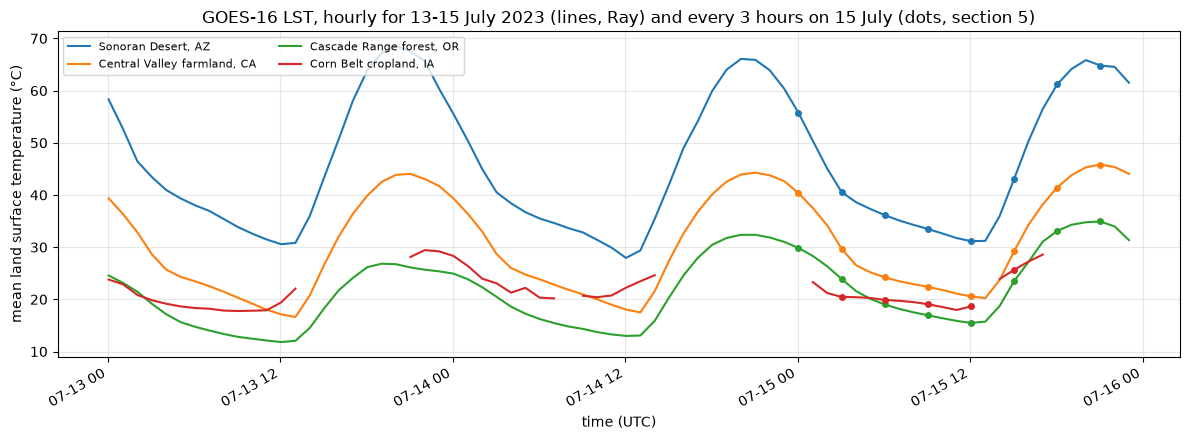

       Sonoran Desert, AZ  Central Valley farmland, CA  \
count                72.0                         72.0   
mean                 46.1                         30.6   
std                  12.9                          9.4   
min                  27.9                         16.6   
25%                  35.0                         22.3   
50%                  42.5                         28.7   
75%                  58.7                         40.0   
max                  68.5                         45.8   

       Cascade Range forest, OR  Corn Belt cropland, IA  
count                      72.0                    47.0  
mean                       21.8                    21.8  
std                         6.9                     3.4  
min                        11.8                    17.8  
25%                        15.7                    19.3  
50%                        21.0                    20.7  
75%                        26.8                    23.6  
max          

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for name in REGIONS:
    line, = ax.plot(hourly.index, hourly[name], "-", label=name)
    ax.plot(day.index, day[name], "o", color=line.get_color(), ms=4)
ax.set_ylabel("mean land surface temperature (°C)")
ax.set_xlabel("time (UTC)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2)
ax.set_title("GOES-16 LST, hourly for 13-15 July 2023 (lines, Ray) and every 3 hours on 15 July (dots, section 5)")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

# The 3-hourly files are a subset of the hourly ones, so the values must match.
common = day.index.intersection(hourly.index)
assert len(common) == len(day)
assert np.allclose(day.loc[common, list(REGIONS)], hourly.loc[common, list(REGIONS)], equal_nan=True)
print(hourly[list(REGIONS)].describe().round(1))

In [10]:
ray.shutdown()